# 05 — Entrenamiento del Modelo Predictivo Multiclase
## Fase 4 · Savia Salud EPS · Analítica Predictiva para Auditoría Prestacional

**Objetivo:** Entrenar, evaluar y comparar modelos de clasificación multiclase (XGBoost, LightGBM, RandomForest) para predecir el estado de auditoría de facturas médicas (Auditada / Glosada / Devuelta).

**Inputs:**
- `data/processed/20260309_train.parquet` — 515,145 filas × 50 cols
- `data/processed/20260309_val.parquet` — 77,843 filas × 50 cols
- `data/processed/20260309_test.parquet` — 40,193 filas × 50 cols
- `data/processed/20260309_feature_list.txt` — 48 features

**Criterios de aceptación:**
- Recall clase Glosada ≥ 0.80
- F1-Score macro ≥ 0.75
- AUC-ROC ≥ 0.85

In [1]:
# =============================================================================
# Celda 1 — Imports y configuración global
# =============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
from pathlib import Path
from datetime import datetime

# Modelos
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

# Métricas
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    recall_score,
    precision_recall_curve,
    average_precision_score,
    ConfusionMatrixDisplay,
)
from sklearn.preprocessing import label_binarize

# Serialización
import joblib

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Rutas
DATA_DIR = Path('../data/processed')
MODELS_DIR = Path('../models/artifacts')
REPORTS_DIR = Path('../reports')
FIGURES_DIR = REPORTS_DIR / 'figures'
EVALS_DIR = REPORTS_DIR / 'evaluations'

MODELS_DIR.mkdir(parents=True, exist_ok=True)
EVALS_DIR.mkdir(parents=True, exist_ok=True)

# Estilo gráficos
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 11,
    'axes.titlesize': 13,
    'figure.figsize': (12, 6),
})

CLASES = {0: 'Auditada', 1: 'Glosada', 2: 'Devuelta'}
DATE_PREFIX = '20260309'

print("✓ Librerías cargadas")
print(f"  XGBoost {xgb.__version__} | LightGBM {lgb.__version__}")
print(f"  sklearn {__import__('sklearn').__version__} | pandas {pd.__version__}")

✓ Librerías cargadas
  XGBoost 3.2.0 | LightGBM 4.6.0
  sklearn 1.5.1 | pandas 2.2.2


## 1. Carga de datos y preparación de matrices X/y

Cargamos los splits temporales generados en Feature Engineering (Fase 3).
División temporal por `fecha_radicacion` — NO aleatoria — previene data leakage.

In [2]:
# =============================================================================
# Celda 2 — Carga de splits y preparación de matrices
# =============================================================================

# Cargar splits
train_df = pd.read_parquet(DATA_DIR / f'{DATE_PREFIX}_train.parquet')
val_df = pd.read_parquet(DATA_DIR / f'{DATE_PREFIX}_val.parquet')
test_df = pd.read_parquet(DATA_DIR / f'{DATE_PREFIX}_test.parquet')

# Cargar lista de features
with open(DATA_DIR / f'{DATE_PREFIX}_feature_list.txt', 'r') as f:
    FEATURES = [line.strip() for line in f if line.strip()]

print(f"Features cargadas: {len(FEATURES)}")

# Separar X / y
X_train, y_train = train_df[FEATURES], train_df['target']
X_val, y_val = val_df[FEATURES], val_df['target']
X_test, y_test = test_df[FEATURES], test_df['target']

# Resumen
print(f"\n{'Split':<8} {'Filas':>8} {'Auditada(0)':>12} {'Glosada(1)':>12} {'Devuelta(2)':>12}")
print("-" * 56)
for name, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    counts = y.value_counts().sort_index()
    print(f"{name:<8} {len(y):>8,} {counts[0]:>12,} {counts[1]:>12,} {counts[2]:>12,}")

# Verificar que no hay NaN en features
nan_counts = X_train.isna().sum()
if nan_counts.sum() > 0:
    print(f"\n⚠️ Features con NaN en train: {nan_counts[nan_counts > 0].to_dict()}")
else:
    print("\n✓ Sin valores NaN en features de entrenamiento")

Features cargadas: 48

Split       Filas  Auditada(0)   Glosada(1)  Devuelta(2)
--------------------------------------------------------
Train     515,145       90,193      330,712       94,240
Val        77,843       17,098       53,145        7,600
Test       40,193       13,723       16,143       10,327

✓ Sin valores NaN en features de entrenamiento


## 2. Cálculo de pesos de clase

El dataset tiene desbalance: Glosada ~64%, Auditada ~18%, Devuelta ~18% en train.
Calculamos `sample_weight` inversamente proporcional a la frecuencia de cada clase
para que el modelo no ignore las clases minoritarias.

In [3]:
# =============================================================================
# Celda 3 — Pesos de clase para manejo de desbalance
# =============================================================================
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

# Calcular pesos inversamente proporcionales
class_weights = compute_class_weight('balanced', classes=np.array([0, 1, 2]), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}

print("Pesos de clase (balanced):")
for cls, w in class_weight_dict.items():
    print(f"  Clase {cls} ({CLASES[cls]}): {w:.4f}")

# Sample weights para XGBoost/LightGBM
sample_weights_train = compute_sample_weight('balanced', y_train)
sample_weights_val = compute_sample_weight('balanced', y_val)

print(f"\n✓ sample_weights calculados — train: {len(sample_weights_train):,}, val: {len(sample_weights_val):,}")

Pesos de clase (balanced):
  Clase 0 (Auditada): 1.9039
  Clase 1 (Glosada): 0.5192
  Clase 2 (Devuelta): 1.8221

✓ sample_weights calculados — train: 515,145, val: 77,843


## 3. Función de evaluación unificada

Función reutilizable que calcula todas las métricas obligatorias (CLAUDE.MD §3.3):
- F1-Score macro
- AUC-ROC (One-vs-Rest)
- Recall por clase (prioridad: Glosada ≥ 0.80)
- Matriz de confusión normalizada

In [4]:
# =============================================================================
# Celda 4 — Función de evaluación unificada
# =============================================================================

def evaluate_model(y_true, y_pred, y_proba, model_name="Modelo"):
    """Evalúa un modelo multiclase con todas las métricas obligatorias.
    
    Args:
        y_true: Etiquetas reales.
        y_pred: Predicciones (clase).
        y_proba: Probabilidades predichas (n_samples, 3).
        model_name: Nombre del modelo para el reporte.
    
    Returns:
        dict con todas las métricas.
    """
    # F1-Score macro
    f1_macro = f1_score(y_true, y_pred, average='macro')
    
    # Recall por clase
    recall_per_class = recall_score(y_true, y_pred, average=None)
    
    # AUC-ROC One-vs-Rest
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2])
    try:
        auc_ovr = roc_auc_score(y_true_bin, y_proba, average='macro', multi_class='ovr')
    except ValueError:
        auc_ovr = float('nan')
    
    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Classification report completo
    report = classification_report(y_true, y_pred, target_names=list(CLASES.values()), output_dict=True)
    
    metrics = {
        'model_name': model_name,
        'f1_macro': f1_macro,
        'auc_roc_ovr': auc_ovr,
        'recall_auditada': recall_per_class[0],
        'recall_glosada': recall_per_class[1],
        'recall_devuelta': recall_per_class[2],
        'confusion_matrix': cm.tolist(),
        'confusion_matrix_normalized': cm_normalized.tolist(),
        'classification_report': report,
    }
    
    # Imprimir resumen
    print(f"\n{'='*60}")
    print(f"  {model_name} — Resultados en Test")
    print(f"{'='*60}")
    print(f"  F1-Score macro:       {f1_macro:.4f}  {'✓' if f1_macro >= 0.75 else '✗'} (meta ≥ 0.75)")
    print(f"  AUC-ROC (OvR):        {auc_ovr:.4f}  {'✓' if auc_ovr >= 0.85 else '✗'} (meta ≥ 0.85)")
    print(f"  Recall Auditada (0):  {recall_per_class[0]:.4f}")
    print(f"  Recall Glosada  (1):  {recall_per_class[1]:.4f}  {'✓' if recall_per_class[1] >= 0.80 else '✗'} (meta ≥ 0.80)")
    print(f"  Recall Devuelta (2):  {recall_per_class[2]:.4f}")
    print(f"{'='*60}")
    print(classification_report(y_true, y_pred, target_names=list(CLASES.values())))
    
    return metrics

print("✓ Función evaluate_model definida")

✓ Función evaluate_model definida


## 4. Modelo 1 — XGBoost (modelo principal)

Configuración base según CLAUDE.MD §4:
- `objective: multi:softprob`, `num_class: 3`
- `eval_metric: [mlogloss, merror]`
- Early stopping en validación para evitar sobreajuste
- `sample_weight` para manejo de desbalance de clases

In [5]:
# =============================================================================
# Celda 5 — Entrenamiento XGBoost
# =============================================================================

xgb_params = {
    'objective': 'multi:softprob',
    'num_class': 3,
    'eval_metric': 'mlogloss',
    'random_state': RANDOM_STATE,
    'n_estimators': 1000,          # alto + early stopping
    'learning_rate': 0.05,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 5,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'early_stopping_rounds': 50,
    'n_jobs': -1,
    'verbosity': 0,
}

print("Entrenando XGBoost...")
t0 = time.time()

xgb_model = xgb.XGBClassifier(**xgb_params)
xgb_model.fit(
    X_train, y_train,
    sample_weight=sample_weights_train,
    eval_set=[(X_val, y_val)],
    sample_weight_eval_set=[sample_weights_val],
    verbose=50,
)

xgb_time = time.time() - t0
print(f"\n✓ XGBoost entrenado en {xgb_time:.1f}s")
print(f"  Mejor iteración: {xgb_model.best_iteration}")
print(f"  Mejor mlogloss (val): {xgb_model.best_score:.4f}")

Entrenando XGBoost...


[0]	validation_0-mlogloss:1.07161


[50]	validation_0-mlogloss:0.66836


[100]	validation_0-mlogloss:0.58287


[150]	validation_0-mlogloss:0.55506


[200]	validation_0-mlogloss:0.54615


... (5 outputs left out)

[500]	validation_0-mlogloss:0.52677


[550]	validation_0-mlogloss:0.52725


[565]	validation_0-mlogloss:0.52637



✓ XGBoost entrenado en 52.1s
  Mejor iteración: 515
  Mejor mlogloss (val): 0.5263


In [6]:
# =============================================================================
# Celda 6 — Evaluación XGBoost en Test
# =============================================================================

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)

xgb_metrics = evaluate_model(y_test, xgb_pred, xgb_proba, model_name="XGBoost")


  XGBoost — Resultados en Test
  F1-Score macro:       0.7490  ✗ (meta ≥ 0.75)
  AUC-ROC (OvR):        0.9078  ✓ (meta ≥ 0.85)
  Recall Auditada (0):  0.7544
  Recall Glosada  (1):  0.7261  ✗ (meta ≥ 0.80)
  Recall Devuelta (2):  0.7628
              precision    recall  f1-score   support

    Auditada       0.65      0.75      0.70     13723
     Glosada       0.80      0.73      0.76     16143
    Devuelta       0.81      0.76      0.78     10327

    accuracy                           0.75     40193
   macro avg       0.75      0.75      0.75     40193
weighted avg       0.75      0.75      0.75     40193



## 5. Modelo 2 — LightGBM (comparación)

In [7]:
# =============================================================================
# Celda 7 — Entrenamiento LightGBM
# =============================================================================

lgb_params = {
    'objective': 'multiclass',
    'num_class': 3,
    'metric': 'multi_logloss',
    'random_state': RANDOM_STATE,
    'n_estimators': 1000,
    'learning_rate': 0.05,
    'max_depth': 6,
    'num_leaves': 50,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_samples': 50,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'n_jobs': -1,
    'verbose': -1,
    'class_weight': 'balanced',
}

print("Entrenando LightGBM...")
t0 = time.time()

lgb_model = lgb.LGBMClassifier(**lgb_params)
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.log_evaluation(50),
        lgb.early_stopping(50),
    ],
)

lgb_time = time.time() - t0
print(f"\n✓ LightGBM entrenado en {lgb_time:.1f}s")
print(f"  Mejor iteración: {lgb_model.best_iteration_}")

Entrenando LightGBM...


Training until validation scores don't improve for 50 rounds


[50]	valid_0's multi_logloss: 0.583298


[100]	valid_0's multi_logloss: 0.54556


[150]	valid_0's multi_logloss: 0.529959


[200]	valid_0's multi_logloss: 0.518854


... (5 outputs left out)

[500]	valid_0's multi_logloss: 0.497703


[550]	valid_0's multi_logloss: 0.497026


[600]	valid_0's multi_logloss: 0.496457


Early stopping, best iteration is:
[584]	valid_0's multi_logloss: 0.496005

✓ LightGBM entrenado en 35.4s
  Mejor iteración: 584


In [8]:
# =============================================================================
# Celda 8 — Evaluación LightGBM en Test
# =============================================================================

lgb_pred = lgb_model.predict(X_test)
lgb_proba = lgb_model.predict_proba(X_test)

lgb_metrics = evaluate_model(y_test, lgb_pred, lgb_proba, model_name="LightGBM")


  LightGBM — Resultados en Test
  F1-Score macro:       0.7441  ✗ (meta ≥ 0.75)
  AUC-ROC (OvR):        0.9063  ✓ (meta ≥ 0.85)
  Recall Auditada (0):  0.7686
  Recall Glosada  (1):  0.7124  ✗ (meta ≥ 0.80)
  Recall Devuelta (2):  0.7433
              precision    recall  f1-score   support

    Auditada       0.64      0.77      0.70     13723
     Glosada       0.81      0.71      0.76     16143
    Devuelta       0.82      0.74      0.78     10327

    accuracy                           0.74     40193
   macro avg       0.75      0.74      0.74     40193
weighted avg       0.75      0.74      0.74     40193



## 6. Modelo 3 — RandomForest (baseline)

In [9]:
# =============================================================================
# Celda 9 — Entrenamiento RandomForest (baseline)
# =============================================================================

rf_params = {
    'n_estimators': 300,
    'max_depth': 15,
    'min_samples_split': 20,
    'min_samples_leaf': 10,
    'class_weight': 'balanced',
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
}

print("Entrenando RandomForest (baseline)...")
t0 = time.time()

rf_model = RandomForestClassifier(**rf_params)
rf_model.fit(X_train, y_train)

rf_time = time.time() - t0
print(f"✓ RandomForest entrenado en {rf_time:.1f}s")

Entrenando RandomForest (baseline)...


✓ RandomForest entrenado en 58.5s


In [10]:
# =============================================================================
# Celda 10 — Evaluación RandomForest en Test
# =============================================================================

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)

rf_metrics = evaluate_model(y_test, rf_pred, rf_proba, model_name="RandomForest")


  RandomForest — Resultados en Test
  F1-Score macro:       0.7217  ✗ (meta ≥ 0.75)
  AUC-ROC (OvR):        0.8966  ✓ (meta ≥ 0.85)
  Recall Auditada (0):  0.8131
  Recall Glosada  (1):  0.7406  ✗ (meta ≥ 0.80)
  Recall Devuelta (2):  0.5854
              precision    recall  f1-score   support

    Auditada       0.60      0.81      0.69     13723
     Glosada       0.81      0.74      0.78     16143
    Devuelta       0.86      0.59      0.70     10327

    accuracy                           0.73     40193
   macro avg       0.76      0.71      0.72     40193
weighted avg       0.75      0.73      0.73     40193



## 7. Comparación de modelos

Tabla comparativa con todas las métricas obligatorias. Se selecciona el mejor modelo
según la métrica primaria: **Recall de la clase Glosada** (clase 1).

In [11]:
# =============================================================================
# Celda 11 — Tabla comparativa de modelos
# =============================================================================

all_metrics = [xgb_metrics, lgb_metrics, rf_metrics]

comparison_data = []
for m in all_metrics:
    comparison_data.append({
        'Modelo': m['model_name'],
        'F1-macro': f"{m['f1_macro']:.4f}",
        'AUC-ROC': f"{m['auc_roc_ovr']:.4f}",
        'Recall Auditada': f"{m['recall_auditada']:.4f}",
        'Recall Glosada': f"{m['recall_glosada']:.4f}",
        'Recall Devuelta': f"{m['recall_devuelta']:.4f}",
    })

comparison_df = pd.DataFrame(comparison_data)
print("\n" + "="*80)
print("  COMPARACIÓN DE MODELOS — Métricas en Test")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Criterios de aceptación
print("\nCriterios de aceptación (CLAUDE.MD §3.3):")
print(f"  Recall Glosada ≥ 0.80 | F1-macro ≥ 0.75 | AUC-ROC ≥ 0.85")

# Seleccionar mejor modelo por recall de Glosada (métrica primaria)
best_idx = np.argmax([m['recall_glosada'] for m in all_metrics])
best_model_name = all_metrics[best_idx]['model_name']
print(f"\n→ Mejor modelo por Recall Glosada: **{best_model_name}**")

# Empate: si hay empate en recall glosada, desempatar por F1-macro
ties = [i for i, m in enumerate(all_metrics) if m['recall_glosada'] == all_metrics[best_idx]['recall_glosada']]
if len(ties) > 1:
    best_idx = max(ties, key=lambda i: all_metrics[i]['f1_macro'])
    best_model_name = all_metrics[best_idx]['model_name']
    print(f"  (Desempate por F1-macro → {best_model_name})")


  COMPARACIÓN DE MODELOS — Métricas en Test
      Modelo F1-macro AUC-ROC Recall Auditada Recall Glosada Recall Devuelta
     XGBoost   0.7490  0.9078          0.7544         0.7261          0.7628
    LightGBM   0.7441  0.9063          0.7686         0.7124          0.7433
RandomForest   0.7217  0.8966          0.8131         0.7406          0.5854

Criterios de aceptación (CLAUDE.MD §3.3):
  Recall Glosada ≥ 0.80 | F1-macro ≥ 0.75 | AUC-ROC ≥ 0.85

→ Mejor modelo por Recall Glosada: **RandomForest**


## 8. Visualizaciones para tesis

- Matrices de confusión normalizadas (3 modelos)
- Importancia de features (Top-20, mejor modelo)
- Curva Precision-Recall para clase Glosada

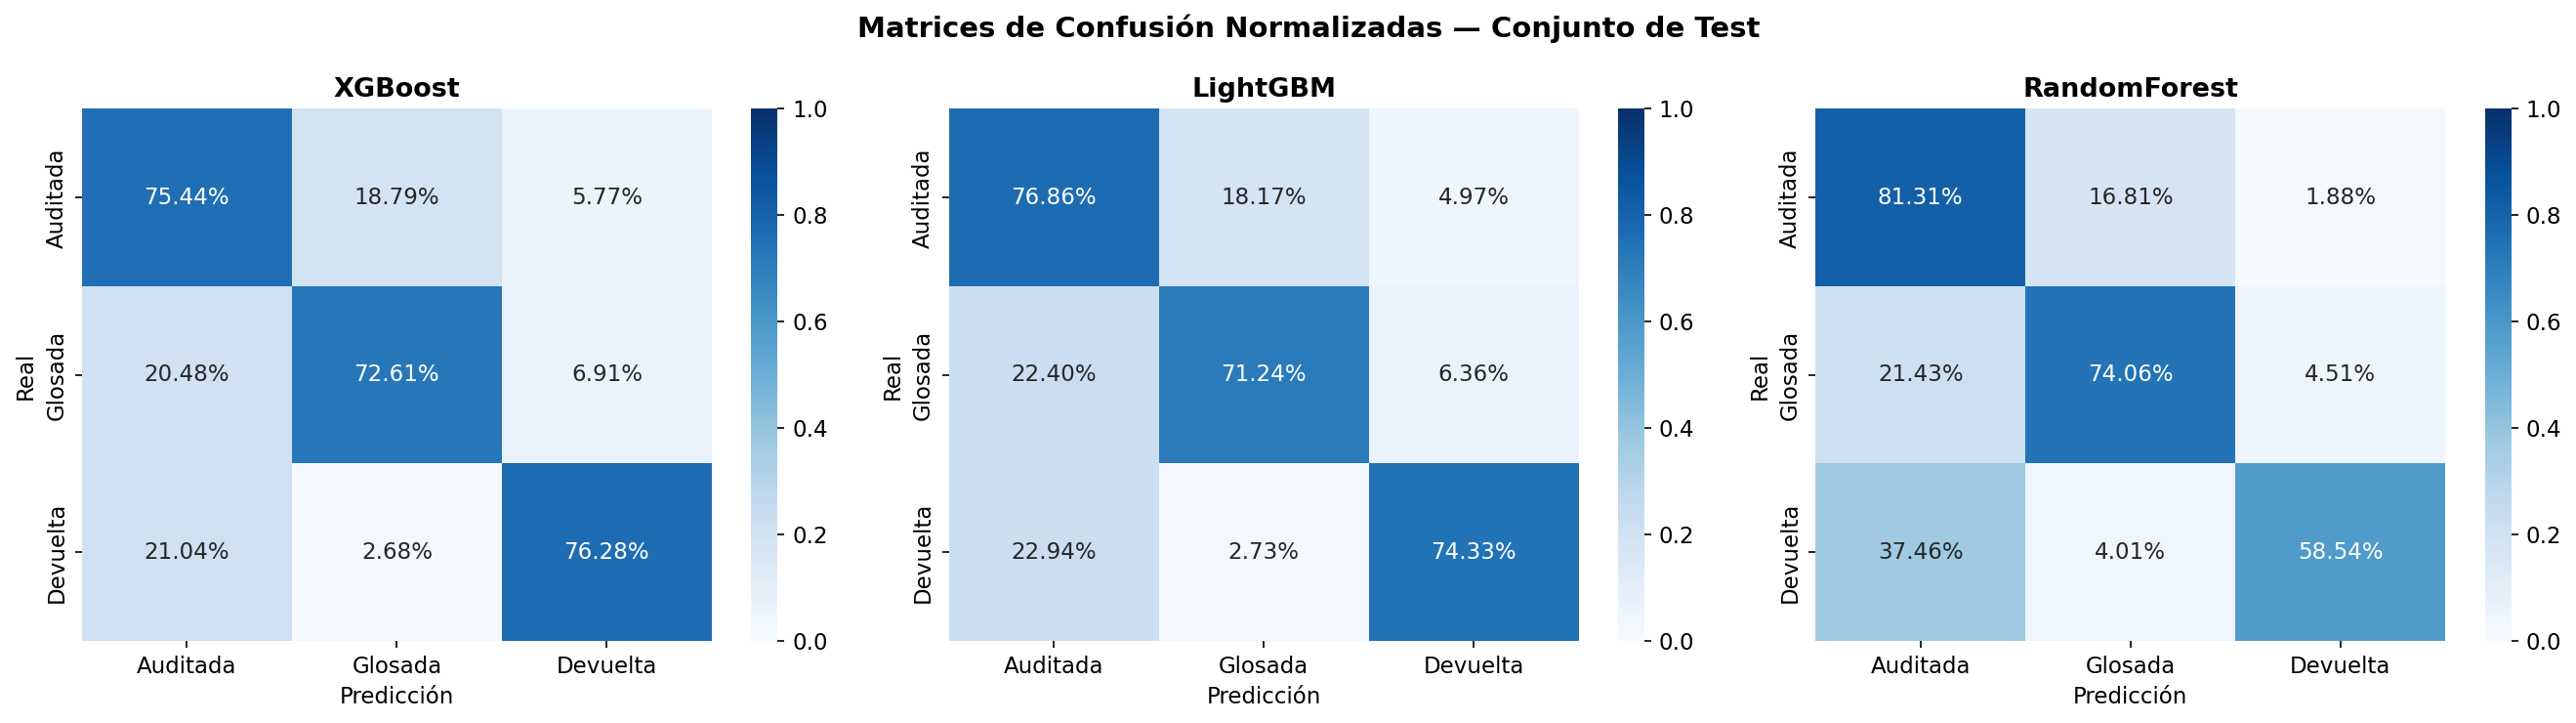

✓ Figura guardada: reports/figures/mt_01_confusion_matrices.png


In [12]:
# =============================================================================
# Celda 12 — Matrices de confusión (3 modelos)
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, m, y_pred_i in zip(axes, all_metrics, [xgb_pred, lgb_pred, rf_pred]):
    cm = np.array(m['confusion_matrix_normalized'])
    sns.heatmap(
        cm, annot=True, fmt='.2%', cmap='Blues',
        xticklabels=list(CLASES.values()),
        yticklabels=list(CLASES.values()),
        ax=ax, vmin=0, vmax=1,
    )
    ax.set_title(m['model_name'], fontweight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

fig.suptitle('Matrices de Confusión Normalizadas — Conjunto de Test', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'mt_01_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Figura guardada: reports/figures/mt_01_confusion_matrices.png")

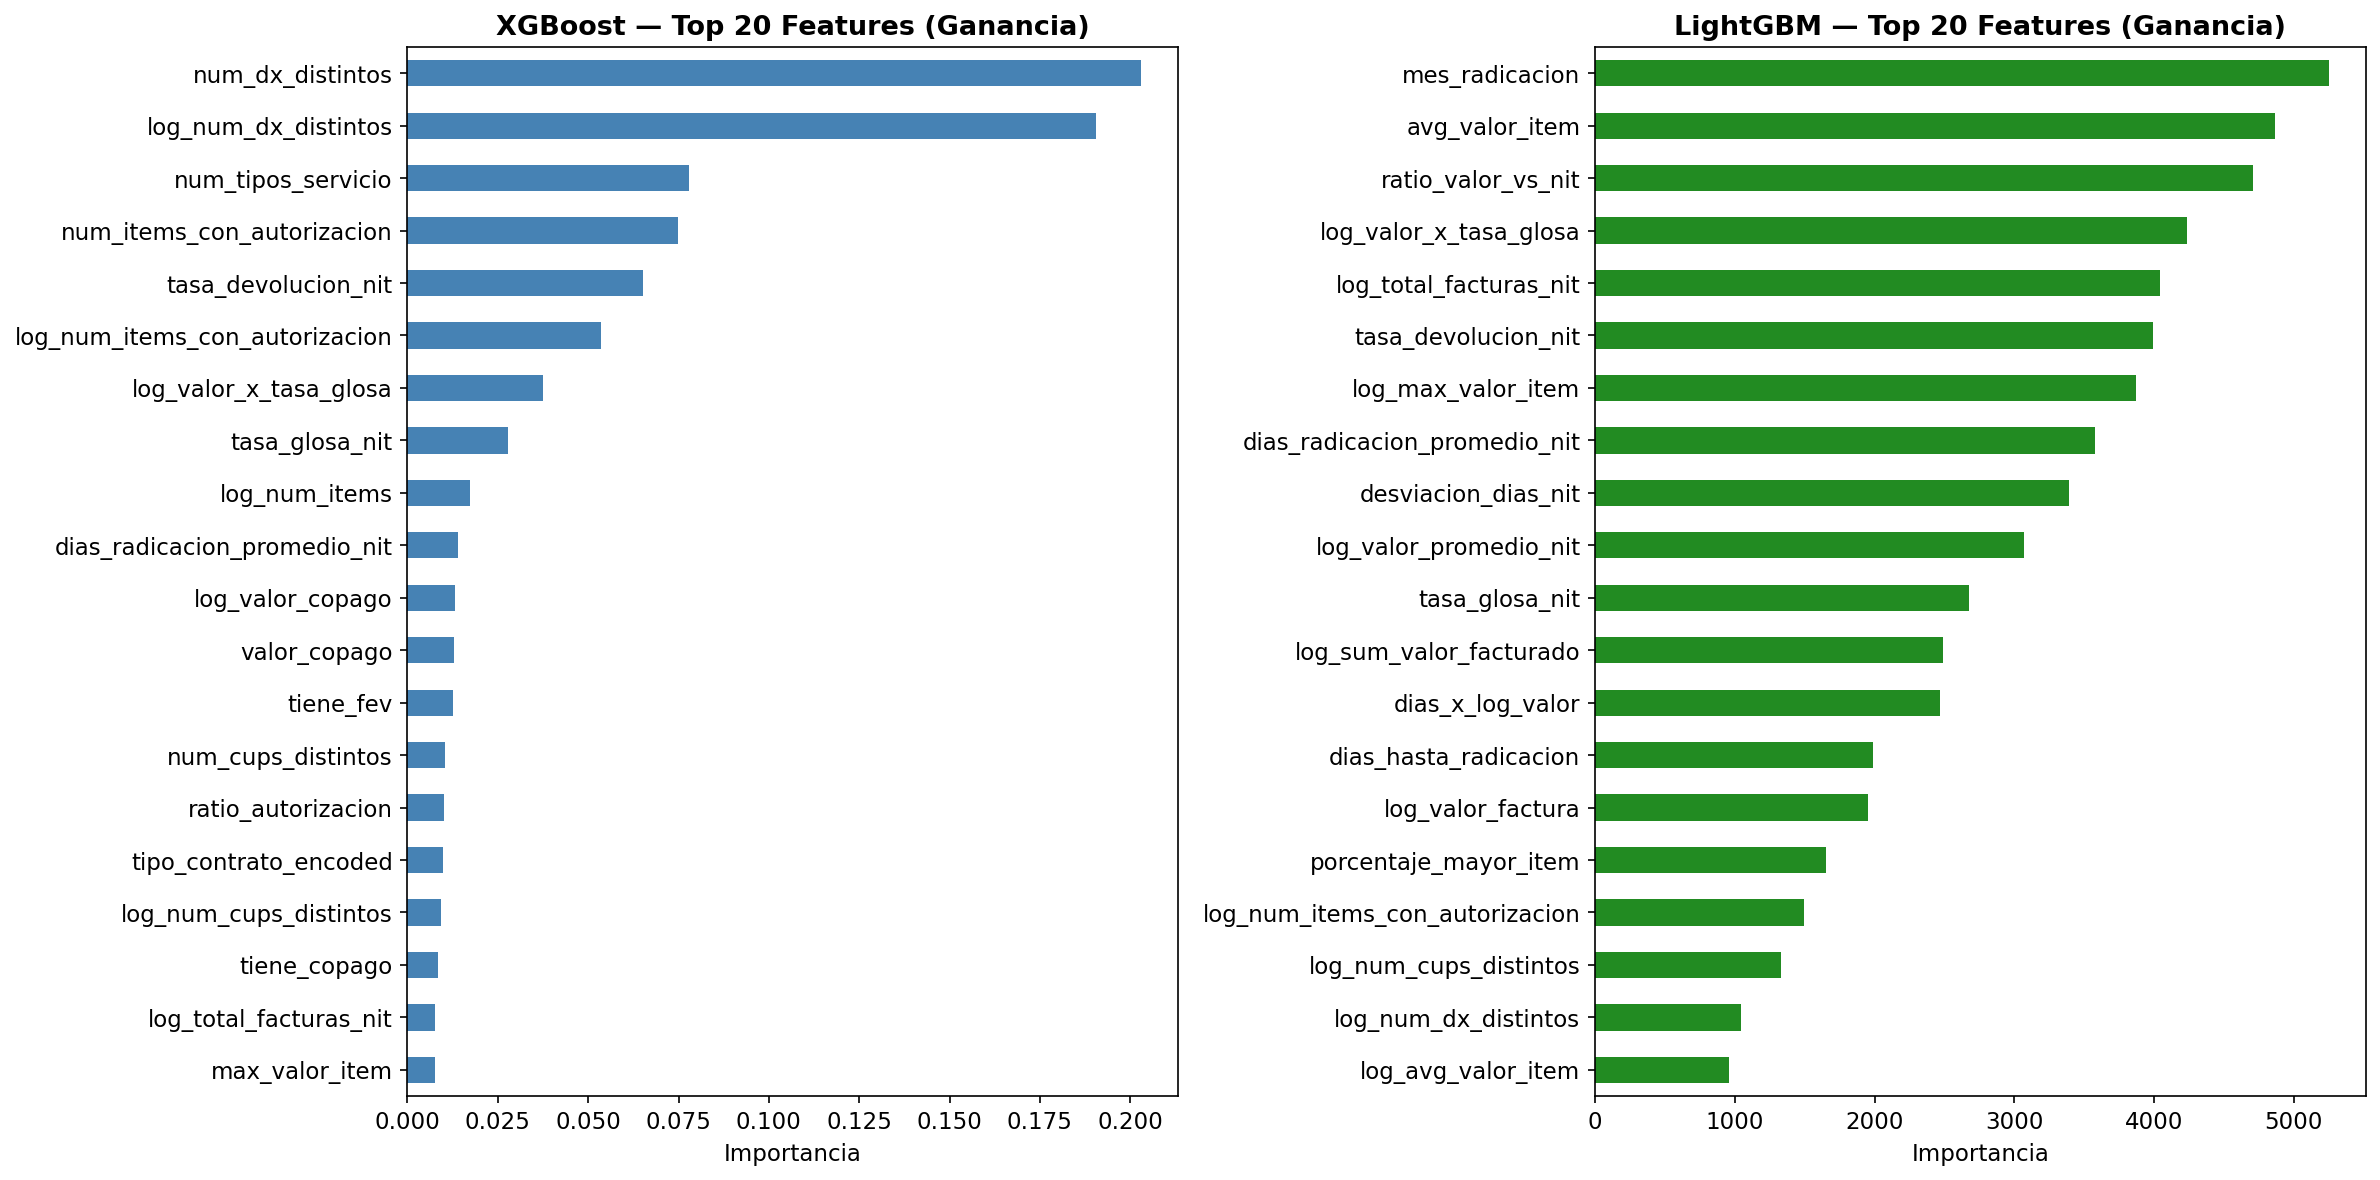

✓ Figura guardada: reports/figures/mt_02_feature_importance.png

Top-10 features XGBoost:
   1. num_dx_distintos                    0.2030
   2. log_num_dx_distintos                0.1906
   3. num_tipos_servicio                  0.0779
   4. num_items_con_autorizacion          0.0748
   5. tasa_devolucion_nit                 0.0652
   6. log_num_items_con_autorizacion      0.0536
   7. log_valor_x_tasa_glosa              0.0375
   8. tasa_glosa_nit                      0.0278
   9. log_num_items                       0.0173
  10. dias_radicacion_promedio_nit        0.0141


In [13]:
# =============================================================================
# Celda 13 — Importancia de features (Top-20, XGBoost + LightGBM)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# XGBoost — importancia por ganancia
xgb_importance = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values(ascending=True)
xgb_importance.tail(20).plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('XGBoost — Top 20 Features (Ganancia)', fontweight='bold')
axes[0].set_xlabel('Importancia')

# LightGBM — importancia por ganancia
lgb_importance = pd.Series(lgb_model.feature_importances_, index=FEATURES).sort_values(ascending=True)
lgb_importance.tail(20).plot.barh(ax=axes[1], color='forestgreen')
axes[1].set_title('LightGBM — Top 20 Features (Ganancia)', fontweight='bold')
axes[1].set_xlabel('Importancia')

plt.tight_layout()
fig.savefig(FIGURES_DIR / 'mt_02_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Figura guardada: reports/figures/mt_02_feature_importance.png")

# Mostrar top-10 en texto
print("\nTop-10 features XGBoost:")
for i, (feat, imp) in enumerate(xgb_importance.tail(10).iloc[::-1].items(), 1):
    print(f"  {i:2d}. {feat:<35s} {imp:.4f}")

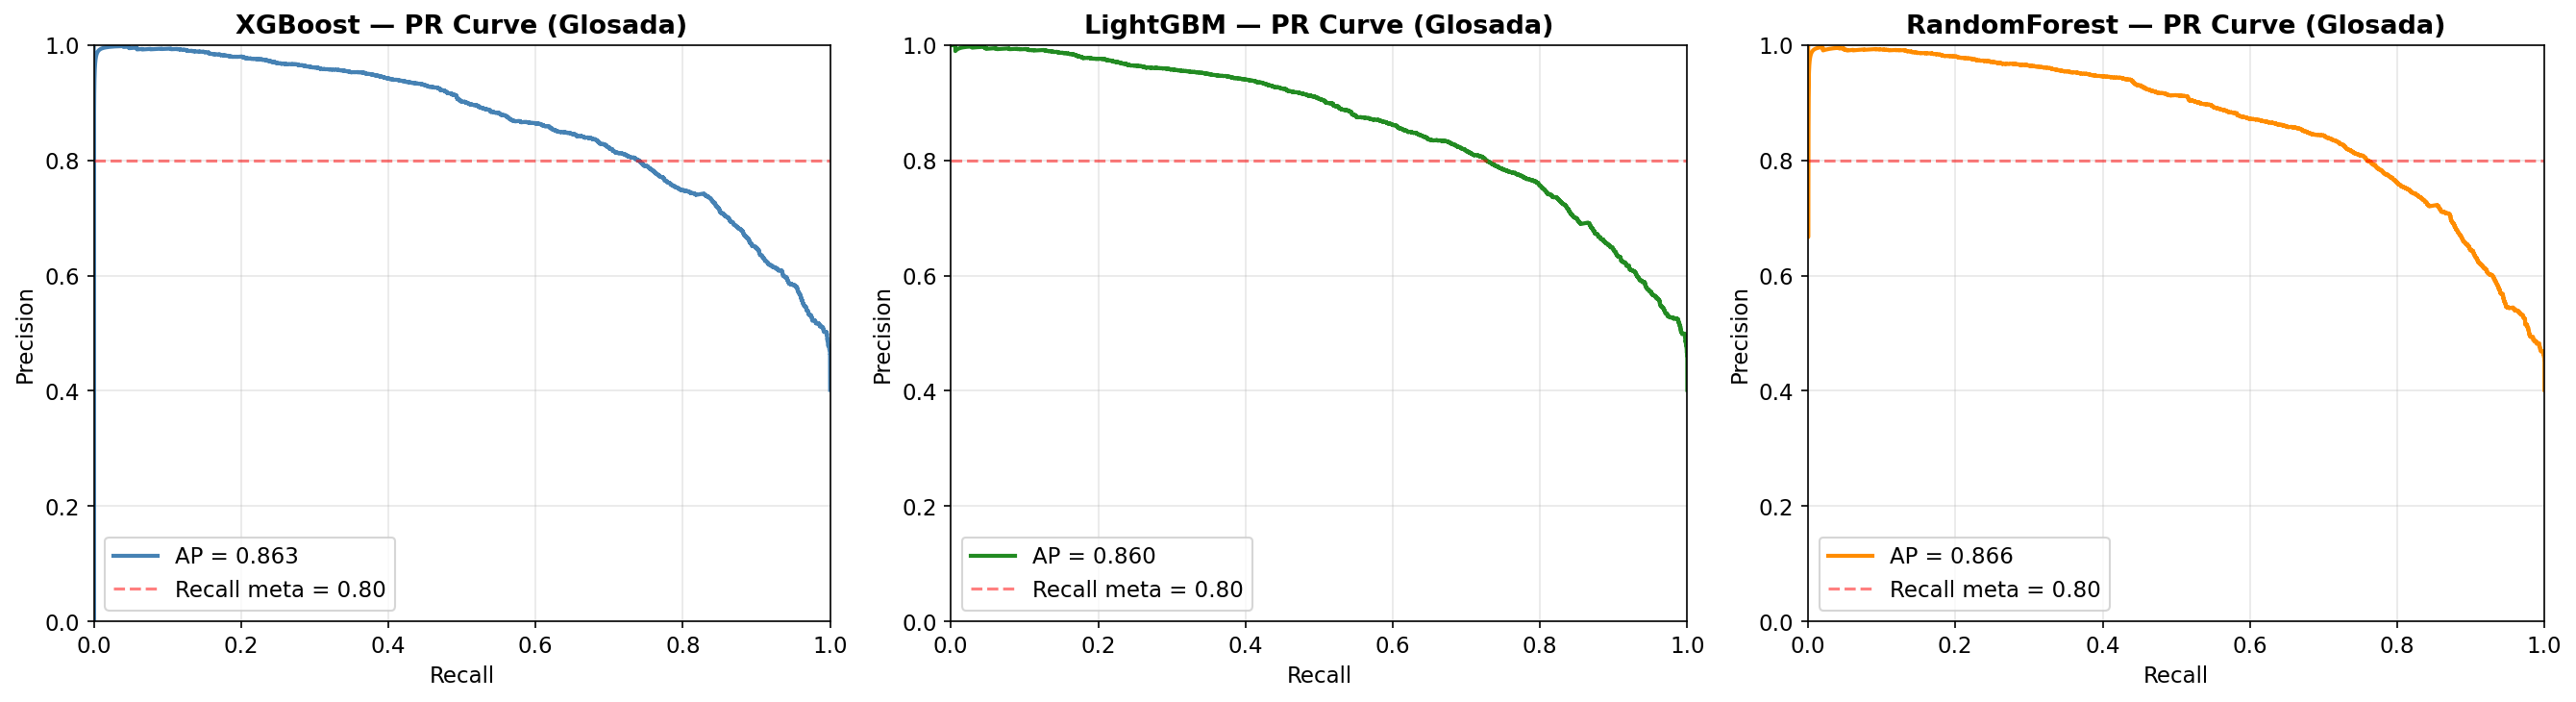

✓ Figura guardada: reports/figures/mt_03_precision_recall_glosada.png


In [14]:
# =============================================================================
# Celda 14 — Curva Precision-Recall para clase Glosada (clase 1)
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = ['steelblue', 'forestgreen', 'darkorange']
models_data = [
    ('XGBoost', xgb_proba),
    ('LightGBM', lgb_proba),
    ('RandomForest', rf_proba),
]

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

for ax, (name, proba), color in zip(axes, models_data, colors):
    # Clase Glosada (1)
    precision, recall, thresholds = precision_recall_curve(y_test_bin[:, 1], proba[:, 1])
    ap = average_precision_score(y_test_bin[:, 1], proba[:, 1])
    
    ax.plot(recall, precision, color=color, lw=2, label=f'AP = {ap:.3f}')
    ax.axhline(y=0.80, color='red', linestyle='--', alpha=0.5, label='Recall meta = 0.80')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'{name} — PR Curve (Glosada)', fontweight='bold')
    ax.legend(loc='lower left')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / 'mt_03_precision_recall_glosada.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Figura guardada: reports/figures/mt_03_precision_recall_glosada.png")

## 9. Análisis de umbral — Clase Glosada

Análisis del impacto de variar el umbral de decisión sobre el recall de la clase Glosada.
El umbral por defecto es 0.75 (CLAUDE.MD §3.3). Evaluamos el trade-off precision/recall.

In [15]:
# =============================================================================
# Celda 15 — Análisis de umbral para clase Glosada (mejor modelo: XGBoost)
# =============================================================================

# Usar probabilidades del mejor modelo (XGBoost por defecto, se ajusta según resultados)
# Para este análisis usamos XGBoost
best_proba = xgb_proba  # Ajustar si otro modelo es mejor

thresholds_to_test = np.arange(0.30, 0.85, 0.05)
threshold_results = []

for thresh in thresholds_to_test:
    # Aplicar umbral: si P(glosada) >= thresh → predecir glosada
    y_custom = np.argmax(best_proba, axis=1)  # predicción base
    glosada_mask = best_proba[:, 1] >= thresh
    y_custom[glosada_mask] = 1
    
    # Si no supera el umbral, usar argmax normal (sin forzar)
    # Recalcular métricas
    recall_glosada = recall_score(y_test, y_custom, average=None)[1]
    f1_m = f1_score(y_test, y_custom, average='macro')
    
    # "Falsos positivos" de glosada: facturas marcadas como glosada que no lo son
    fp_glosada = ((y_custom == 1) & (y_test != 1)).sum()
    tp_glosada = ((y_custom == 1) & (y_test == 1)).sum()
    precision_glosada = tp_glosada / (tp_glosada + fp_glosada) if (tp_glosada + fp_glosada) > 0 else 0
    
    threshold_results.append({
        'Umbral': f"{thresh:.2f}",
        'Recall Glosada': f"{recall_glosada:.4f}",
        'Precision Glosada': f"{precision_glosada:.4f}",
        'F1-macro': f"{f1_m:.4f}",
        'FP Glosada': fp_glosada,
    })

thresh_df = pd.DataFrame(threshold_results)
print("Análisis de umbral — Clase Glosada (XGBoost)")
print("="*70)
print(thresh_df.to_string(index=False))
print("\nUmbral por defecto en producción: 0.75 (configurable en src/models/predict.py)")

Análisis de umbral — Clase Glosada (XGBoost)
Umbral Recall Glosada Precision Glosada F1-macro  FP Glosada
  0.30         0.8310            0.7385   0.7435        4750
  0.35         0.7876            0.7557   0.7422        4110
  0.40         0.7621            0.7784   0.7470        3502
  0.45         0.7430            0.7961   0.7500        3073
  0.50         0.7261            0.8041   0.7490        2855
  0.55         0.7261            0.8041   0.7490        2855
  0.60         0.7261            0.8041   0.7490        2855
  0.65         0.7261            0.8041   0.7490        2855
  0.70         0.7261            0.8041   0.7490        2855
  0.75         0.7261            0.8041   0.7490        2855
  0.80         0.7261            0.8041   0.7490        2855

Umbral por defecto en producción: 0.75 (configurable en src/models/predict.py)


## 10. Serialización del mejor modelo

Guardamos el modelo ganador en `models/artifacts/` en formato nativo JSON (XGBoost)
o joblib (LightGBM/RF), junto con las métricas en JSON para integración LaTeX.

In [16]:
# =============================================================================
# Celda 16 — Serialización del mejor modelo y métricas
# =============================================================================

# Guardar XGBoost en formato nativo JSON (CLAUDE.MD §3.3)
xgb_model_path = MODELS_DIR / f'{DATE_PREFIX}_xgboost_v1.json'
xgb_model.save_model(str(xgb_model_path))
print(f"✓ XGBoost guardado: {xgb_model_path}")

# Guardar LightGBM con joblib
lgb_model_path = MODELS_DIR / f'{DATE_PREFIX}_lightgbm_v1.joblib'
joblib.dump(lgb_model, str(lgb_model_path))
print(f"✓ LightGBM guardado: {lgb_model_path}")

# Guardar RandomForest con joblib
rf_model_path = MODELS_DIR / f'{DATE_PREFIX}_randomforest_v1.joblib'
joblib.dump(rf_model, str(rf_model_path))
print(f"✓ RandomForest guardado: {rf_model_path}")

# Guardar métricas en JSON para integración LaTeX
metrics_output = {
    'fecha_entrenamiento': datetime.now().isoformat(),
    'date_prefix': DATE_PREFIX,
    'num_features': len(FEATURES),
    'features': FEATURES,
    'train_size': len(X_train),
    'val_size': len(X_val),
    'test_size': len(X_test),
    'modelos': {},
}

for m in all_metrics:
    name = m['model_name']
    metrics_output['modelos'][name] = {
        'f1_macro': m['f1_macro'],
        'auc_roc_ovr': m['auc_roc_ovr'],
        'recall_auditada': m['recall_auditada'],
        'recall_glosada': m['recall_glosada'],
        'recall_devuelta': m['recall_devuelta'],
        'confusion_matrix': m['confusion_matrix'],
        'classification_report': m['classification_report'],
    }

metrics_path = EVALS_DIR / f'{DATE_PREFIX}_metricas.json'
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_output, f, indent=2, ensure_ascii=False, default=str)

print(f"✓ Métricas guardadas: {metrics_path}")

# Resumen de archivos generados
print(f"\n{'='*60}")
print("  ARCHIVOS GENERADOS — Fase 4")
print(f"{'='*60}")
print(f"  Modelos:")
print(f"    {xgb_model_path}")
print(f"    {lgb_model_path}")
print(f"    {rf_model_path}")
print(f"  Métricas:")
print(f"    {metrics_path}")
print(f"  Figuras:")
print(f"    reports/figures/mt_01_confusion_matrices.png")
print(f"    reports/figures/mt_02_feature_importance.png")
print(f"    reports/figures/mt_03_precision_recall_glosada.png")
print(f"{'='*60}")

✓ XGBoost guardado: ..\models\artifacts\20260309_xgboost_v1.json


✓ LightGBM guardado: ..\models\artifacts\20260309_lightgbm_v1.joblib


✓ RandomForest guardado: ..\models\artifacts\20260309_randomforest_v1.joblib


✓ Métricas guardadas: ..\reports\evaluations\20260309_metricas.json

  ARCHIVOS GENERADOS — Fase 4
  Modelos:
    ..\models\artifacts\20260309_xgboost_v1.json
    ..\models\artifacts\20260309_lightgbm_v1.joblib
    ..\models\artifacts\20260309_randomforest_v1.joblib
  Métricas:
    ..\reports\evaluations\20260309_metricas.json
  Figuras:
    reports/figures/mt_01_confusion_matrices.png
    reports/figures/mt_02_feature_importance.png
    reports/figures/mt_03_precision_recall_glosada.png
